# ecg-records quickstart

Research and engineering software; not a medical device. Requires `pip install "ecg-records[engine,viz,table]" ecginterpret`.

In [1]:
import io
from IPython.display import Image

import ecgfeat
from ecgfeat import viz


def show(figure, dpi=80):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=dpi)
    return Image(buffer.getvalue())


ecgfeat.__version__, ecgfeat.list_examples()

('0.3.1', ['af', 'lbbb', 'sinus'])

## A signal

The bundled examples are PTB-XL records (CC BY 4.0). `ecgfeat.read_signal(path)` reads WFDB, EDF/BDF, CSV and NumPy files the same way.

In [2]:
signal = ecgfeat.load_example("lbbb")
signal

SignalData(12 leads ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6'], 10 s @ 500 Hz, mV)

## Measure

In [3]:
record = ecgfeat.ecg_record(signal, profile="all")
print(record.summary())

ECG Record rec-8a88205c8af8c258dad5465c2f87070acd51d8f53b0a2b5b6c95bb1a9333e4b9 (schema 1.1.0, profile all)
12 leads · 12 beats · 10.0 s at 500 Hz · amplitude mV · quality Q1 (usable)
Rate      heart rate 70 /min · atrial rate 71 /min · min 68 /min · max 75 /min
Intervals P 122 ms · PR 158 ms · QRS 134 ms · QT 443 ms · QTc Bazett 476 ms · QTc Fridericia 464 ms
Axes      P 40° · QRS -23° · T 108° · QRS-T angle 131°
Rhythm    RR mean 856 ms · RR SD 25 ms · RMSSD 17 ms · organized P 25% · paced 0%
Voltage   Sokolow-Lyon 3215 µV · Cornell 2054 µV
Research and engineering software; not a medical device.


In [4]:
record.get("qrs_duration_ms"), record.get("median_r_amplitude_uv", lead="V6"), record.get("qrs_duration_ms", lead="V1", beat=2)

(134, 777, 128)

In [5]:
result = record.query("qt_interval_ms")
result.value, result.unit, result.feature_state, str(result.address)

(443,
 'ms',
 {'status': 'observed', 'reason': 'value_available'},
 'ecg-record:rec-8a88205c8af8c258dad5465c2f87070acd51d8f53b0a2b5b6c95bb1a9333e4b9@1.1.0#/measurements/global/qt_interval_ms/values')

## Tables

In [6]:
record.to_dataframe("global")[["value", "unit", "state", "validation"]].head(12)

,value,unit,state,validation
name,,,,
heart_rate_bpm,70.0,1/min,observed,unvalidated
frontal_qrs_axis_deg,-23.0,deg,observed,unvalidated
qtc_bazett_ms,476.0,ms,observed,unvalidated
qrs_wide_ms,134.0,ms,observed,unvalidated
p_duration_ms,122.0,ms,observed,benchmark_validated
pr_interval_ms,158.0,ms,observed,benchmark_validated
qrs_duration_ms,134.0,ms,observed,benchmark_validated
qt_interval_ms,443.0,ms,observed,benchmark_validated
qtc_fridericia_ms,464.0,ms,observed,unvalidated


In [7]:
record.to_dataframe("leads")[["median_r_amplitude_uv", "median_s_amplitude_uv", "median_st_j_uv", "median_st_60ms_uv", "median_t_amplitude_uv"]]

name,median_r_amplitude_uv,median_s_amplitude_uv,median_st_j_uv,median_st_60ms_uv,median_t_amplitude_uv
lead,,,,,
I,1049.0,0.0,-21.0,-63.0,-145.0
II,608.0,-253.0,9.0,30.0,386.0
III,0.0,0.0,27.0,87.0,433.0
aVR,0.0,0.0,11.0,13.0,1.0
aVL,1086.0,0.0,-21.0,-80.0,-274.0
aVF,180.0,-733.0,17.0,60.0,396.0
V1,171.0,-2438.0,187.0,269.0,659.0
V2,261.0,-2319.0,237.0,341.0,900.0
V3,206.0,-968.0,112.0,169.0,598.0


## Plots

Every function returns `(figure, axes)`; a new ECG-paper figure is sized in real millimetres.

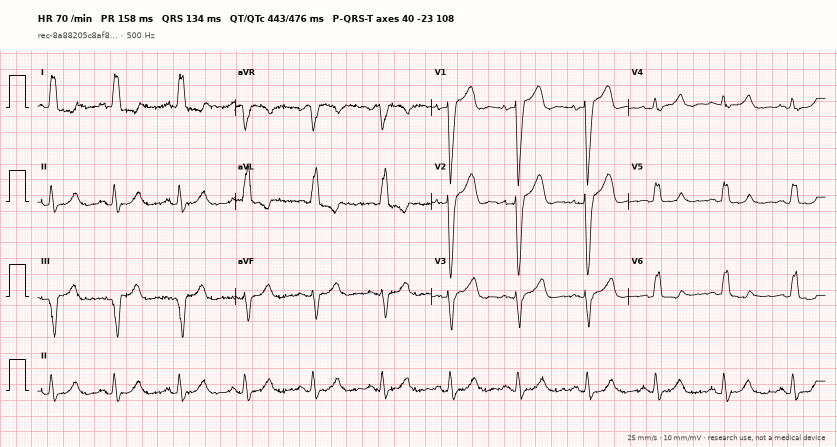

In [8]:
figure, ax = viz.plot_ecg(signal, record)
show(figure)

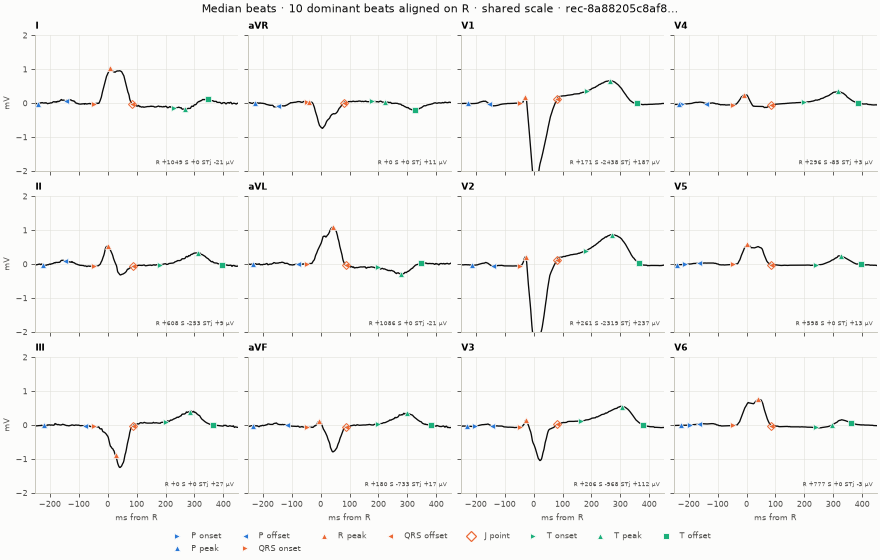

In [9]:
figure, axes = viz.plot_median_beats(signal, record)
show(figure)

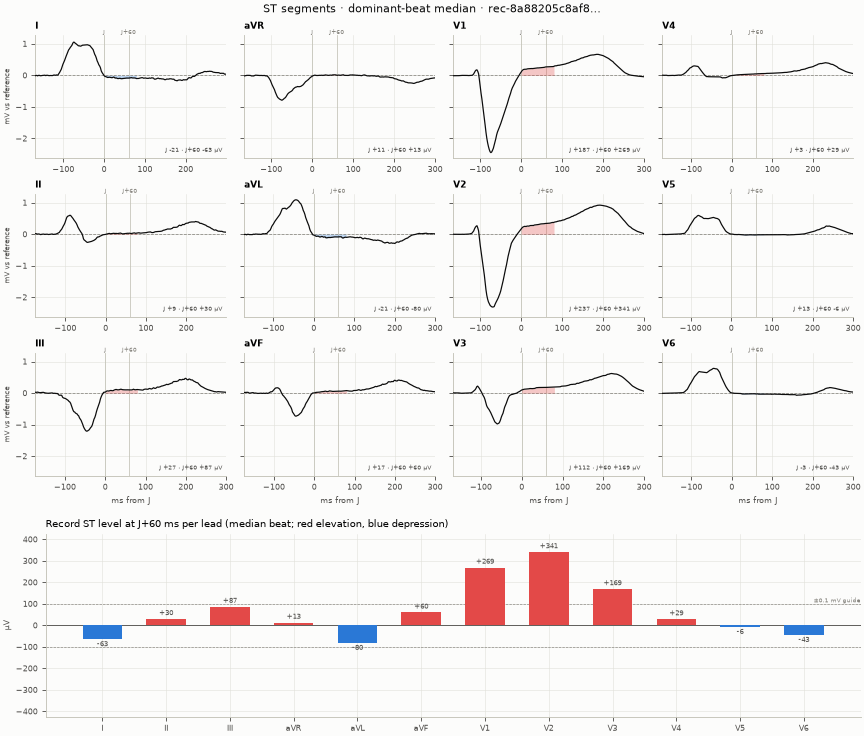

In [10]:
figure, axes = viz.plot_st_segments(signal, record)
show(figure)

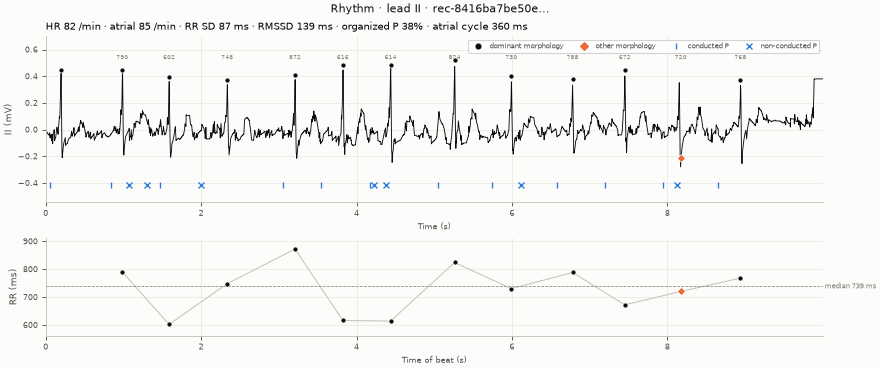

In [11]:
af = ecgfeat.load_example("af")
figure, axes = viz.plot_rhythm(af, ecgfeat.ecg_record(af, profile="all"))
show(figure)

## Interpret (optional `ecginterpret`)

`analyze` measures once and returns the record and the Interpretation document.

In [12]:
from ecginterpret import analyze, render_report

record, document = analyze(signal, profile="all")
print(render_report(document, record))

ECG rule-based interpretation report
Record rec-8a88205c8af8c258dad5465c2f87070acd51d8f53b0a2b5b6c95bb1a9333e4b9
Status: technically_limited_with_findings · ecginterpret 0.2.1 (document 1.0.0)

Measurements
  Rate      heart rate 70 /min · atrial rate 71 /min · min 68 /min · max 75 /min
  Intervals P 122 ms · PR 158 ms · QRS 134 ms · QT 443 ms · QTc Bazett 476 ms · QTc Fridericia 464 ms
  Axes      P 40° · QRS -23° · T 108° · QRS-T angle 131°
  Rhythm    RR mean 856 ms · RR SD 25 ms · RMSSD 17 ms · organized P 25% · paced 0%
  Voltage   Sokolow-Lyon 3215 µV · Cornell 2054 µV

Statements
  - [abnormal] ECG pattern consistent with left bundle branch block (conduction, medium confidence)
  - [abnormal] Secondary T-wave abnormality associated with altered ventricular activation or hypertrophy (repolarization, medium confidence)
  - [normal] Sinus rhythm (rhythm, high confidence)
  - [observation] Wide-QRS repolarization interval review using JT/JTc (intervals, low confidence)
  - [observat